# Movement with matrices

These graphs show scaling, translation, and rotation of a rectangle in BrushCue. Positive y points down. Run this notebook from the monorepo checkout so it can load the book font.


In [ ]:
import math
import os
from pathlib import Path
from textwrap import wrap

import brushcue as bc

REPO_ROOT = next((directory for directory in (Path.cwd(), *Path.cwd().parents)
                  if (directory / "writing/graphics/fonts").is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Run this notebook from the monorepo checkout")
os.chdir(REPO_ROOT)
UNIT = 100
SCALE = (2 / 3, 4 / 3)
TRANSLATION = (2, 1)
BLUE = (0.10, 0.42, 0.72)
PURPLE = (0.55, 0.20, 0.70)
ORANGE = (0.90, 0.32, 0.04)
BLACK = (0, 0, 0)
SHAPE_FILL_ALPHA = 0.20
EXAMPLES = ("initial", "scale", "translation", "rotation", "center_rotation",
            "top_left_rotation", "composite")


def translate(points, offset):
    return [(x + offset[0], y + offset[1]) for x, y in points]


def rotate(points, degrees):
    c, s = math.cos(math.radians(degrees)), math.sin(math.radians(degrees))
    return [(c * x - s * y, s * x + c * y) for x, y in points]


def pivot_stages(points, pivot, degrees):
    moved = translate(points, (-pivot[0], -pivot[1]))
    turned = rotate(moved, degrees)
    return moved, turned, translate(turned, pivot)


def composite_matrix():
    """Scale, rotate 45 degrees about center, then 60 about the tracked corner."""
    root2, root6 = math.sqrt(2), math.sqrt(6)
    return (
        ((root2 - root6) / 6, -(root6 + root2) / 3, 1 + root2 / 2),
        ((root6 + root2) / 6, (root2 - root6) / 3, 2 - 3 * root2 / 2),
        (0, 0, 1),
    )


def example_geometry(name):
    """Return the preceding shape, colored stages, pivot and explanatory note."""
    initial = [(0, 0), (3, 0), (3, 3), (0, 3)]
    scaled = [(x * SCALE[0], y * SCALE[1]) for x, y in initial]
    translated = translate(scaled, TRANSLATION)
    centered = pivot_stages(scaled, (1, 2), 45)[-1]
    corner = centered[0]  # Track the original top-left vertex after rotation.
    final = pivot_stages(centered, corner, 60)[-1]
    pivot, note = None, None
    if name == "initial":
        return None, [(initial, ORANGE, "Original 3 x 3 square")], pivot, note
    if name == "scale":
        before, after = initial, scaled
    elif name == "translation":
        before, after = scaled, translated
    elif name == "rotation":
        before, after = translated, rotate(translated, 45)
        pivot = (0, 0)
        note = "Center: (3, 3) -> (0, 4.24); pivot: origin"
    elif name in ("center_rotation", "top_left_rotation"):
        if name == "center_rotation":
            before, pivot, degrees = scaled, (1, 2), 45
            note = "Original and final center: (1, 2)"
        else:
            before, pivot, degrees = centered, corner, 60
            note = f"Original and final top-left: ({pivot[0]:.3f}, {pivot[1]:.3f})"
        moved, turned, restored = pivot_stages(before, pivot, degrees)
        # Round only the legend text; geometry retains full precision.
        px, py = pivot
        stages = [
            (moved, BLUE, f"1. Move by ({-px:.3g}, {-py:.3g})"),
            (turned, PURPLE, f"2. Rotate {degrees} degrees clockwise"),
            (restored, ORANGE, f"3. Move back by ({px:.3g}, {py:.3g})"),
        ]
        return before, stages, pivot, note
    elif name == "composite":
        matrix = composite_matrix()
        before = initial
        after = [tuple(row[0] * x + row[1] * y + row[2] for row in matrix[:2])
                 for x, y in initial]
        assert all(math.isclose(a, b, abs_tol=1e-12)
                   for p, q in zip(after, final) for a, b in zip(p, q))
        note = "Scale, rotate 45 degrees about center, then 60 degrees about top-left"
    else:
        raise ValueError(f"Unknown example: {name}")
    return before, [(after, ORANGE, "After transformation")], pivot, note


def color(rgb, alpha=1):
    return bc.ProfiledColor.from_rgba_srgb(bc.RGBAColor.from_components(*rgb, alpha))


def fill(rgb, alpha=1):
    return bc.RenderStyle.fill_only(bc.Fill.solid(color(rgb, alpha)))


def draw_graph(name):
    before, stages, pivot, note = example_geometry(name)
    all_points = (before or []) + [p for points, _, _ in stages for p in points]
    # Keep equal units and a small margin, with extra negative space only when used.
    xmin = min(-2, math.floor(min(x for x, _ in all_points) - 0.35))
    xmax = max(4, math.ceil(max(x for x, _ in all_points) + 0.35))
    ymin = min(-1, math.floor(min(y for _, y in all_points) - 0.35))
    ymax = max(4, math.ceil(max(y for _, y in all_points) + 0.35))
    left, top = 65, 55
    right, bottom = left + (xmax - xmin) * UNIT, top + (ymax - ymin) * UNIT
    origin = (left - xmin * UNIT, top - ymin * UNIT)
    note_lines = wrap(note, width=34) if note else []
    legend_rows = int(before is not None) + len(stages) + len(note_lines)
    legend_x = right + 55
    legend_top = max(top + 15, (top + bottom - legend_rows * 38) / 2)
    width, height = legend_x + 400, bottom + 55
    identity = bc.Transform2.identity().to_list()
    font = bc.Font.from_path("writing/graphics/fonts/LibertinusSerif-Regular.otf")
    painter = bc.Painter.new().add_rectangle_with_render_style(
        bc.Point2f.from_components(width / 2, height / 2),
        bc.Vector2f.from_components(width, height), 0, fill((0, 0, 0), 0), identity,
    )

    def pixel(point):
        return (origin[0] + point[0] * UNIT, origin[1] + point[1] * UNIT)

    def path(points, style, closed=False):
        nonlocal painter
        curve = bc.Path.new().move_to_point(bc.Point2f.from_components(*points[0]))
        for p in points[1:] + (points[:1] if closed else []):
            curve = curve.line_to_point(bc.Point2f.from_components(*p))
        # Geometry is already transformed: strokes and dashes stay fixed in pixels.
        painter = painter.add_path_with_render_style(curve, style, identity)

    def stroke(rgb, radius=1.5, dashed=False, alpha=1):
        brush = (bc.Brush.dashed(color(rgb, alpha), 10, color(BLACK, 0), 8, radius)
                 if dashed else bc.Brush.solid(color(rgb, alpha), radius))
        return bc.RenderStyle.brush_only(brush)

    def label(text, position, rgb=BLACK, size=24):
        nonlocal painter

        @bc.brushcue_fn
        def style(character):
            return bc.StyledCharacter.new(character, font, size, fill(rgb))

        characters = bc.String(bc.input_parsers.parse_string_graph(text)).to_character_list()
        painter = painter.add_styled_text(bc.StyledString.styled_string_from_characters_free(
            characters.to_stream().map(style).collect(), bc.Point2f.from_components(*position),
        ))

    for i in range(xmin, xmax + 1):
        x = pixel((i, 0))[0]
        path([(x, top), (x, bottom)], stroke(BLACK, 0.7, alpha=0.28))
        if i:
            label(str(i), (x - 8, origin[1] - 30), size=21)
    for i in range(ymin, ymax + 1):
        y = pixel((0, i))[1]
        path([(left, y), (right, y)], stroke(BLACK, 0.7, alpha=0.28))
        if i:
            label(str(i), (origin[0] - 30, y - 13), size=21)

    for points, rgb, _ in stages:
        path([pixel(p) for p in points], fill(rgb, SHAPE_FILL_ALPHA), True)
    if before:
        path([pixel(p) for p in before], stroke(BLUE, dashed=True), True)
    for points, rgb, _ in stages:
        path([pixel(p) for p in points], stroke(rgb, 2), True)

    ox, oy = origin
    path([(left - 10, oy), (right + 20, oy)], stroke(BLACK))
    path([(right + 8, oy - 6), (right + 20, oy), (right + 8, oy + 6)], stroke(BLACK))
    path([(ox, top - 10), (ox, bottom + 20)], stroke(BLACK))
    path([(ox - 6, bottom + 8), (ox, bottom + 20), (ox + 6, bottom + 8)], stroke(BLACK))
    label("x", (right + 32, oy - 16), size=29)
    label("y", (ox + 16, bottom + 6), size=29)
    label("(0, 0)", (ox - 85, oy - 30), size=21)

    if pivot is not None:
        x, y = pixel(pivot)
        path([(x - 7, y - 7), (x + 7, y + 7)], stroke(BLACK, 2))
        path([(x - 7, y + 7), (x + 7, y - 7)], stroke(BLACK, 2))
    if name == "rotation":
        arc = [pixel((math.sqrt(18) * math.cos(math.pi / 4 + math.pi / 4 * i / 48),
                      math.sqrt(18) * math.sin(math.pi / 4 + math.pi / 4 * i / 48)))
               for i in range(49)]
        path(arc, stroke(BLACK))
        x, y = arc[-1]
        path([(x + 12, y - 6), (x, y), (x + 12, y + 6)], stroke(BLACK))
        for point in [(3, 3), (0, math.sqrt(18))]:
            x, y = pixel(point)
            path([(x - 6, y - 6), (x + 6, y + 6)], stroke(BLACK, 2))
            path([(x - 6, y + 6), (x + 6, y - 6)], stroke(BLACK, 2))

    row = 0
    if before:
        y = legend_top
        path([(legend_x, y + 10), (legend_x + 35, y + 10)], stroke(BLUE, dashed=True))
        label("Before this transformation", (legend_x + 50, y), size=22)
        row += 1
    for _, rgb, text in stages:
        y = legend_top + row * 38
        path([(legend_x, y + 10), (legend_x + 35, y + 10)], stroke(rgb, 2))
        label(text, (legend_x + 50, y), size=22)
        row += 1
    for note_line in note_lines:
        label(note_line, (legend_x, legend_top + row * 38), size=21)
        row += 1
    return bc.Composition.painter(painter)


ctx = bc.Context()
from IPython.display import Image, display


## Initial


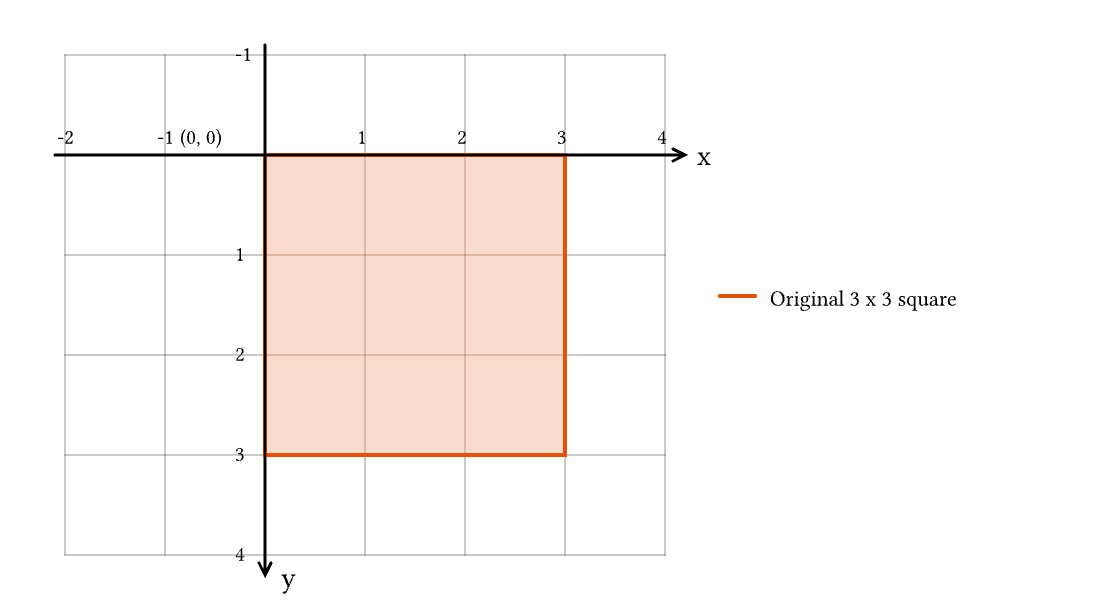

In [ ]:
display(Image(data=bytes(draw_graph("initial").execute(ctx).to_image_bytes(ctx))))


## Scale


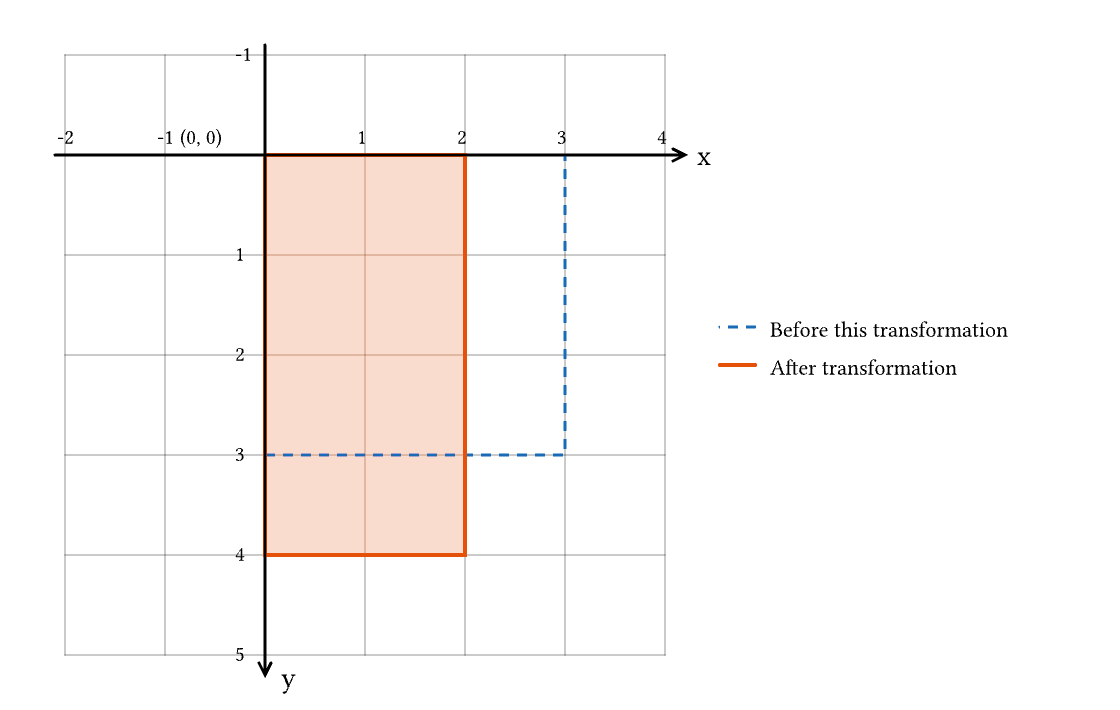

In [ ]:
display(Image(data=bytes(draw_graph("scale").execute(ctx).to_image_bytes(ctx))))


## Translation


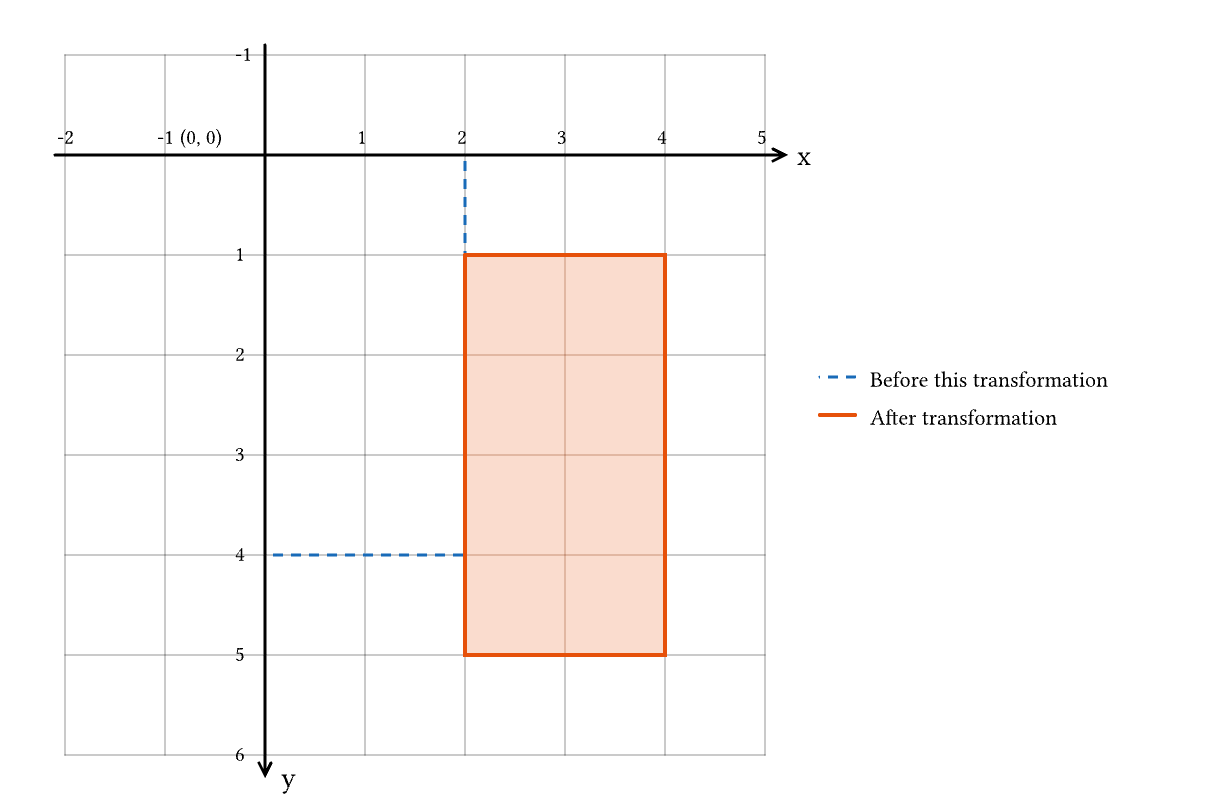

In [ ]:
display(Image(data=bytes(draw_graph("translation").execute(ctx).to_image_bytes(ctx))))


## Rotation


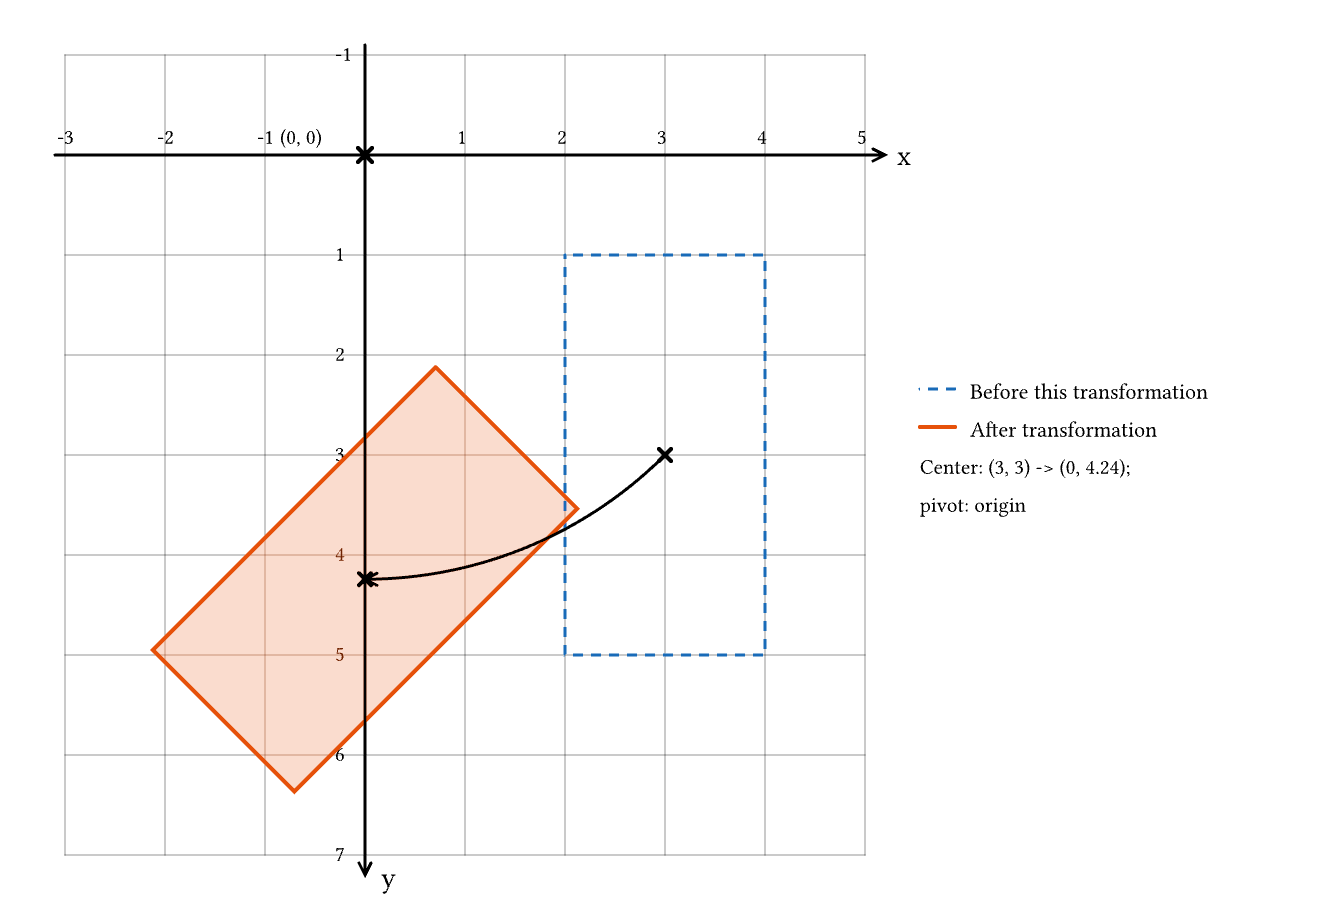

In [ ]:
display(Image(data=bytes(draw_graph("rotation").execute(ctx).to_image_bytes(ctx))))


## Center Rotation


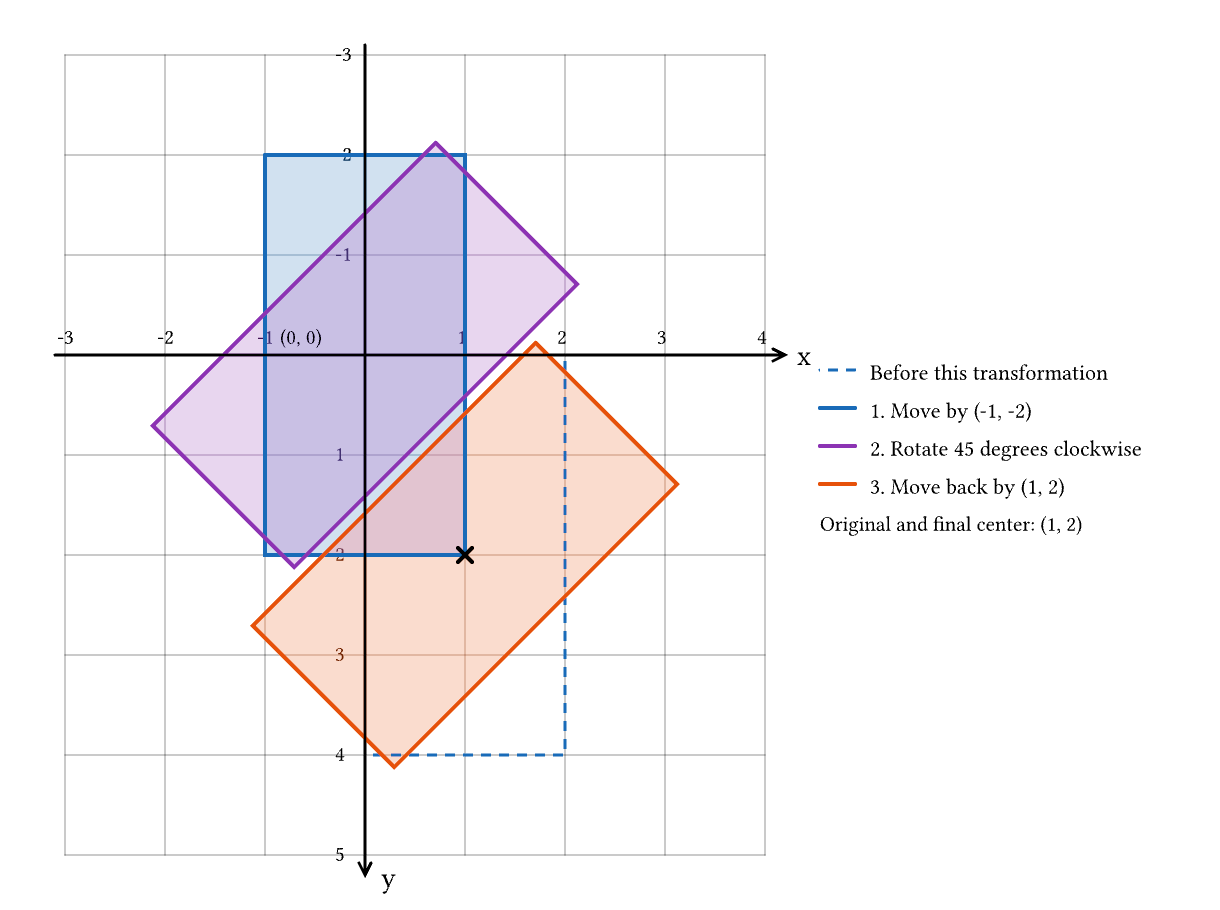

In [ ]:
display(Image(data=bytes(draw_graph("center_rotation").execute(ctx).to_image_bytes(ctx))))


## Top Left Rotation


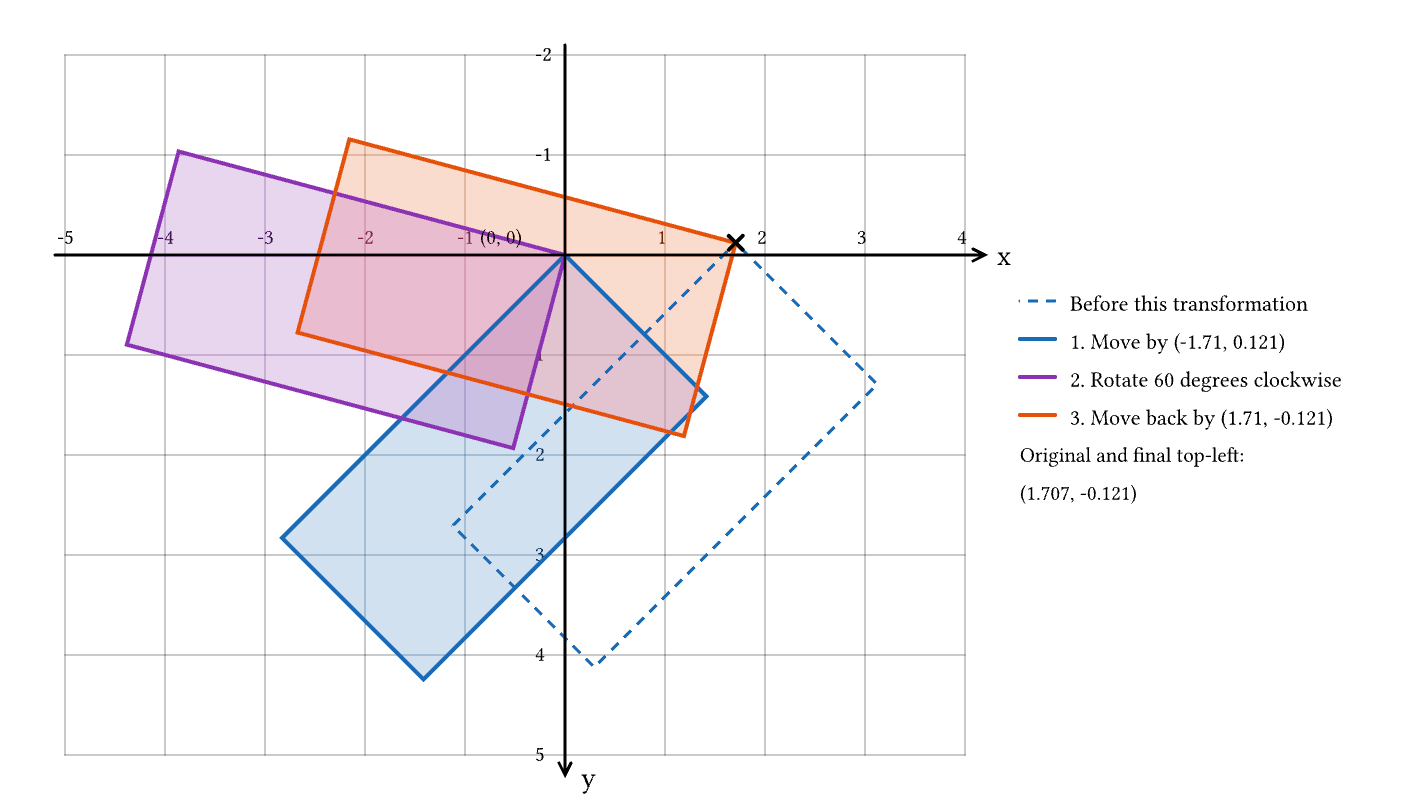

In [ ]:
display(Image(data=bytes(draw_graph("top_left_rotation").execute(ctx).to_image_bytes(ctx))))


## Composite


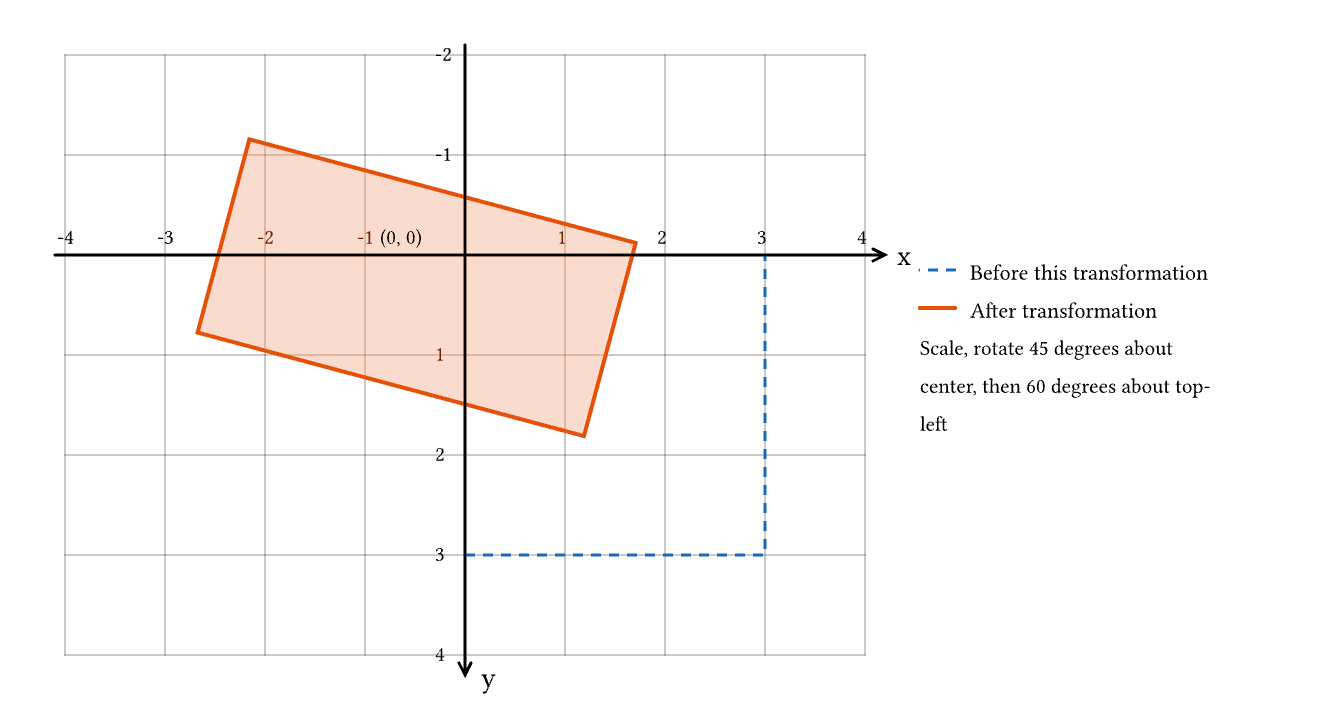

In [ ]:
display(Image(data=bytes(draw_graph("composite").execute(ctx).to_image_bytes(ctx))))
